# 03 · Duplicates — which documents are re-publications of each other?

Two very different signals live in this checkout, and mixing them up is the
easiest way to misread a run:

| signal | where | what it means | decided by |
| --- | --- | --- | --- |
| **collapsed duplicates** | `outputs-replica/*/_reports/duplicates.csv`, `duplicate_groups` in `global.json` | these pairs *are* the same bytes | full SHA-256, or the head/tail range probe |
| **candidate duplicates** | `outputs/*/_reports/candidate_duplicates.csv` | these pairs *look* the same — same listed size, similar name | a dry-run heuristic; **never** verified by hash |

This notebook works through both and ends with the audit question: which rows
should you re-check before trusting them.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


## 1 · The collapsed duplicates (verified)

In [2]:
dups = d.load_duplicates("outputs-replica")
run = d.load_manifest("outputs-replica")
groups = d.duplicate_groups("outputs-replica")


base = d.name_of  # last URL/path segment, percent-decoded


view = dups.assign(
    size=dups["size"].map(d.human_bytes),
    kept=dups["kept_url"].map(base),
    duplicate=dups["duplicate_path"].map(base),
)[["site", "size", "method", "action", "kept", "duplicate"]]
display(view.sort_values(["site", "kept"]).reset_index(drop=True))

print(f"{len(dups)} collapses across {len(groups)} distinct content hashes")
print("methods:", dups["method"].value_counts().to_dict())
print("actions:", dups["action"].value_counts().to_dict())

,site,size,method,action,kept,duplicate
0,comissaodaverdade.al.sp.gov.br,88.0 KiB,sha256,stored as hardlink,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf
1,comissaodaverdade.al.sp.gov.br,33.0 KiB,sha256,stored as hardlink,001-ArquivoCEMDP-devanir.pdf,001-ArquivoCEMDP.pdf
2,dados.cvm.gov.br,96.0 KiB,sha256,stored as hardlink,cia_aberta_doc_2025.zip,fidc_doc_2025.zip
3,dadosabertos.pgfn.gov.br,300.0 KiB,range-probe,stored as hardlink,Dados_abertos_FGTS.zip,Dados_abertos_FGTS.zip
4,dadosabertos.pgfn.gov.br,320.0 KiB,range-probe,stored as hardlink,Dados_abertos_Nao_Previdenciario.zip,Dados_abertos_Nao_Previdenciario.zip
5,dadosabertos.pgfn.gov.br,420.0 KiB,range-probe,stored as hardlink,Dados_abertos_Previdenciario.zip,Dados_abertos_Previdenciario.zip
6,macau.rn.gov.br,150.0 KiB,sha256,stored as hardlink,macau-2013-01-02.pdf,macau-2013-03-11-edicao-2.pdf
7,valiprev.sp.gov.br,3.7 KiB,sha256,stored as hardlink,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...
8,valiprev.sp.gov.br,3.7 KiB,sha256,stored as hardlink,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...


9 collapses across 8 distinct content hashes
methods: {'sha256': 6, 'range-probe': 3}
actions: {'stored as hardlink': 9}


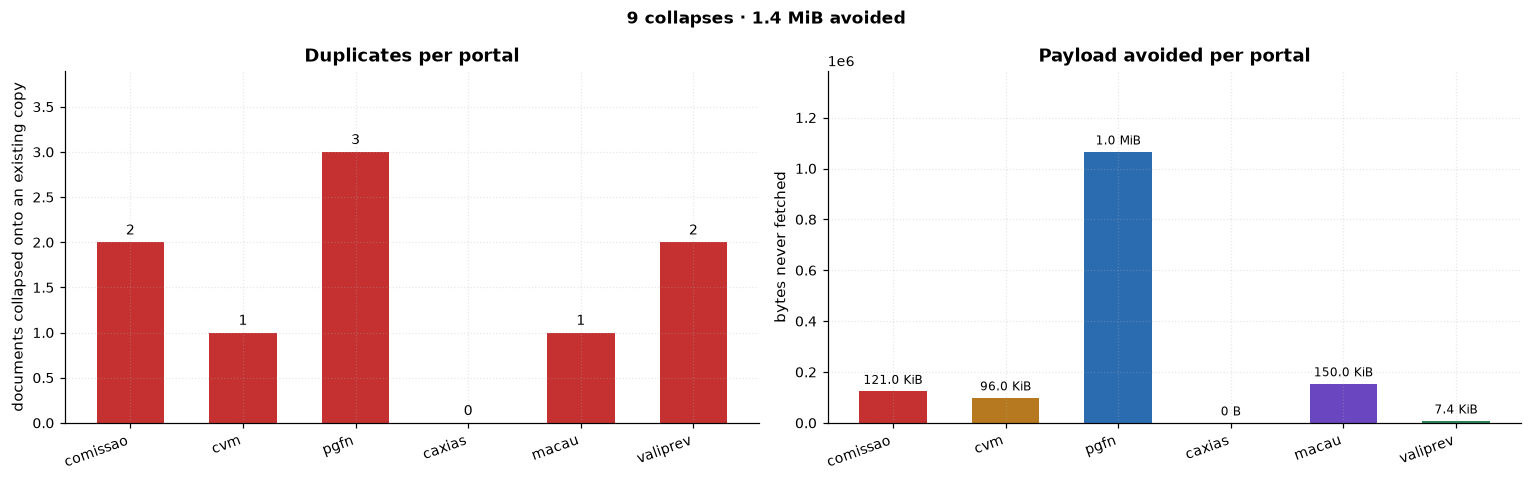

,documents,collapses,duplicate rate,saved
site,,,,
comissaodaverdade.al.sp.gov.br,8,2.0,25.0,121.0 KiB
dados.cvm.gov.br,5,1.0,20.0,96.0 KiB
dadosabertos.pgfn.gov.br,7,3.0,42.9,1.0 MiB
geofiles.caxias.rs.gov.br,6,0.0,0.0,0 B
macau.rn.gov.br,5,1.0,20.0,150.0 KiB
valiprev.sp.gov.br,8,2.0,25.0,7.4 KiB


In [3]:
by_site = (
    dups.groupby("site")
    .agg(collapses=("size", "count"), bytes_collapsed=("size", "sum"))
    .reindex(d.load_summary("outputs-replica")["site"])
    .fillna(0)
)
discovered = run.groupby("site")["url"].count().reindex(by_site.index).fillna(0)
by_site["documents"] = discovered
by_site["duplicate rate"] = (by_site["collapses"] / by_site["documents"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
x = range(len(by_site))

bars = axes[0].bar(x, by_site["collapses"].to_numpy(dtype=float), color="#c53030", width=0.6)
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels([d.short_site(s) for s in by_site.index], rotation=20, ha="right")
axes[0].set_ylabel("documents collapsed onto an existing copy")
axes[0].set_title("Duplicates per portal")
axes[0].set_ylim(0, by_site["collapses"].max() * 1.3)

bars = axes[1].bar(x, by_site["bytes_collapsed"].to_numpy(dtype=float), color=d.colors_for(by_site.index), width=0.6)
axes[1].bar_label(bars, labels=[d.human_bytes(v) for v in by_site["bytes_collapsed"]], padding=3, fontsize=8)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels([d.short_site(s) for s in by_site.index], rotation=20, ha="right")
axes[1].set_ylabel("bytes never fetched")
axes[1].set_title("Payload avoided per portal")
axes[1].set_ylim(0, by_site["bytes_collapsed"].max() * 1.3)

fig.suptitle(
    f"{int(by_site['collapses'].sum())} collapses · {d.human_bytes(by_site['bytes_collapsed'].sum())} avoided",
    fontweight="bold",
)
fig.tight_layout()
plt.show()

display(by_site.assign(saved=by_site["bytes_collapsed"].map(d.human_bytes))[["documents", "collapses", "duplicate rate", "saved"]])

## 2 · The duplicate groups

`global.json → duplicate_groups` keys the collapses by content hash, so one group
can hold more than two copies (the Valiprev LGPD artefact appears three times).
Sizes here are the payload the group represents.

,site,sha256 (12),copies,size (human),method,kept,duplicates
0,dadosabertos.pgfn.gov.br,46280c782398,2,420.0 KiB,range-probe,Dados_abertos_Previdenciario.zip,Dados_abertos_Previdenciario.zip
1,dadosabertos.pgfn.gov.br,b3f1d00fb562,2,320.0 KiB,range-probe,Dados_abertos_Nao_Previdenciario.zip,Dados_abertos_Nao_Previdenciario.zip
2,dadosabertos.pgfn.gov.br,f82f79411cd8,2,300.0 KiB,range-probe,Dados_abertos_FGTS.zip,Dados_abertos_FGTS.zip
3,macau.rn.gov.br,b4183265d26e,2,150.0 KiB,sha256,macau-2013-01-02.pdf,macau-2013-03-11-edicao-2.pdf
4,dados.cvm.gov.br,a92b87949ab0,2,96.0 KiB,sha256,cia_aberta_doc_2025.zip,fidc_doc_2025.zip
5,comissaodaverdade.al.sp.gov.br,302000e3cd88,2,88.0 KiB,sha256,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf
6,comissaodaverdade.al.sp.gov.br,c395464b53db,2,33.0 KiB,sha256,001-ArquivoCEMDP-devanir.pdf,001-ArquivoCEMDP.pdf
7,valiprev.sp.gov.br,a077779091c9,3,3.7 KiB,sha256,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...


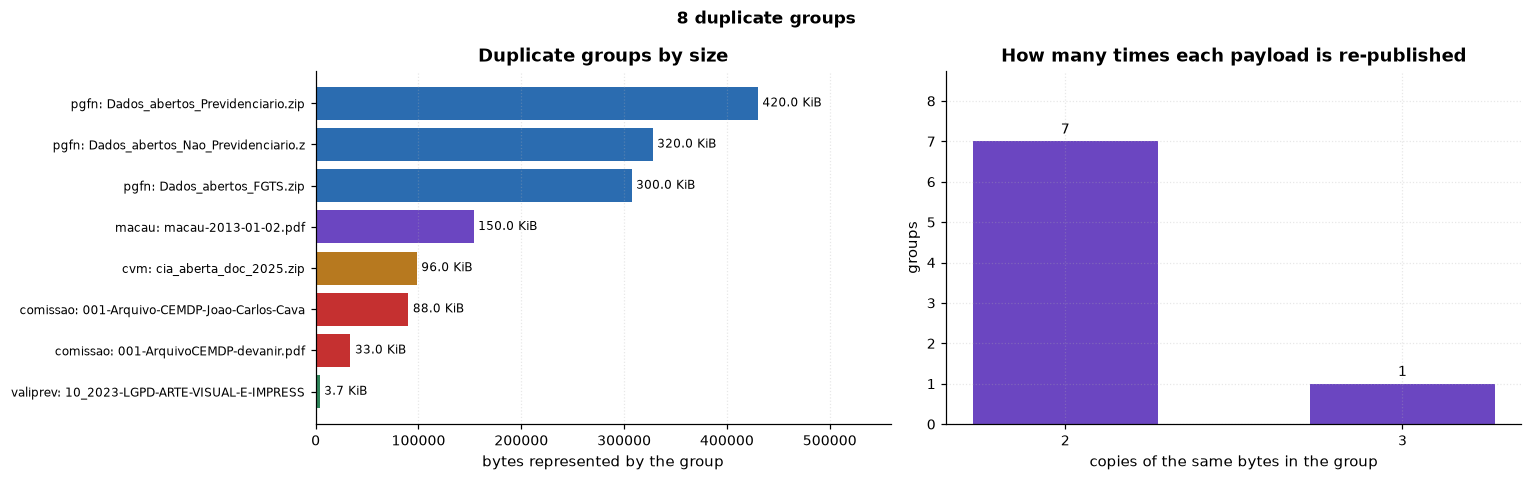

In [4]:
rows = []
for sha, recs in groups.items():
    rows.append(
        {
            "sha256 (12)": sha[:12],
            "site": recs[0]["site"],
            "size": recs[0]["size"],
            "size (human)": d.human_bytes(recs[0]["size"]),
            "method": ", ".join(sorted({r["method"] for r in recs})),
            "copies": len(recs) + 1,
            "kept": base(recs[0]["kept_url"]),
            "duplicates": ", ".join(base(r["duplicate_url"]) for r in recs),
        }
    )
gtab = pd.DataFrame(rows).sort_values("size", ascending=False).reset_index(drop=True)
display(gtab[["site", "sha256 (12)", "copies", "size (human)", "method", "kept", "duplicates"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
g = gtab.iloc[::-1]
bars = axes[0].barh(
    [f"{d.short_site(s)}: {k[:34]}" for s, k in zip(g["site"], g["kept"])],
    g["size"].to_numpy(dtype=float),
    color=d.colors_for(g["site"]),
)
axes[0].bar_label(bars, labels=list(g["size (human)"]), padding=3, fontsize=8)
axes[0].set_xlabel("bytes represented by the group")
axes[0].set_title("Duplicate groups by size")
axes[0].set_xlim(0, g["size"].max() * 1.3)
axes[0].tick_params(axis="y", labelsize=8)
axes[0].grid(axis="y", visible=False)

copies = gtab["copies"].value_counts().sort_index()
axes[1].bar([str(i) for i in copies.index], copies.to_numpy(dtype=float), color="#6b46c1", width=0.55)
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=9)
axes[1].set_xlabel("copies of the same bytes in the group")
axes[1].set_ylabel("groups")
axes[1].set_title("How many times each payload is re-published")
axes[1].set_ylim(0, copies.max() * 1.25)

fig.suptitle(f"{len(gtab)} duplicate groups", fontweight="bold")
fig.tight_layout()
plt.show()

## 3 · How do the duplicate names differ?

Portals re-publish the same bytes under a new name. Knowing the naming habit of
a portal is what makes the *heuristic* in the next section plausible — and it is
also why name similarity alone can never be proof.

,site,method,kept,duplicate,difference
0,comissaodaverdade.al.sp.gov.br,sha256,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf,digit(s) appended: '004'
1,comissaodaverdade.al.sp.gov.br,sha256,001-ArquivoCEMDP-devanir.pdf,001-ArquivoCEMDP.pdf,text removed: '-devanir'
2,dados.cvm.gov.br,sha256,cia_aberta_doc_2025.zip,fidc_doc_2025.zip,other
3,dadosabertos.pgfn.gov.br,range-probe,Dados_abertos_FGTS.zip,Dados_abertos_FGTS.zip,identical name
4,dadosabertos.pgfn.gov.br,range-probe,Dados_abertos_Nao_Previdenciario.zip,Dados_abertos_Nao_Previdenciario.zip,identical name
5,dadosabertos.pgfn.gov.br,range-probe,Dados_abertos_Previdenciario.zip,Dados_abertos_Previdenciario.zip,identical name
6,macau.rn.gov.br,sha256,macau-2013-01-02.pdf,macau-2013-03-11-edicao-2.pdf,other
7,valiprev.sp.gov.br,sha256,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,digit(s) removed from kept: '1'
8,valiprev.sp.gov.br,sha256,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO-CONSELHO-DISP...,other


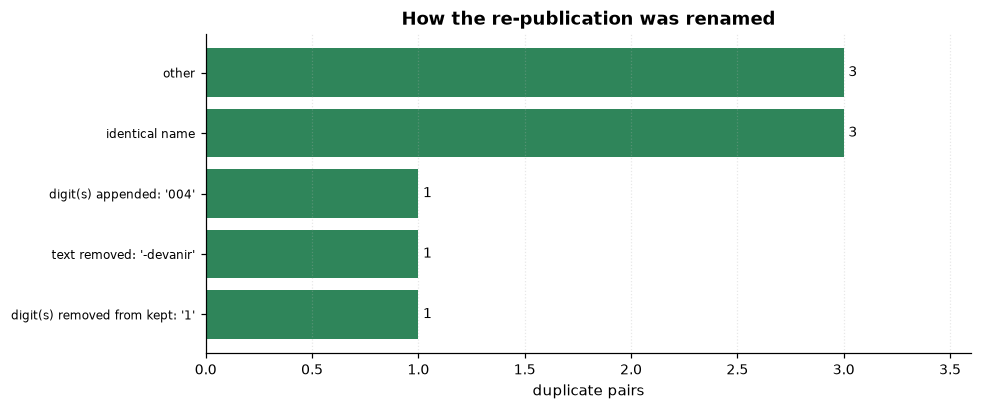

In [5]:
import os as _os


def transform(kept: str, dup: str) -> str:
    k, e1 = _os.path.splitext(str(kept))
    n, e2 = _os.path.splitext(str(dup))
    if str(kept) == str(dup):
        return "identical name"
    if e1.lower() != e2.lower():
        return "different extension"
    if n == k + "1" or (n.startswith(k) and n[len(k):].isdigit()):
        return f"digit(s) appended: '{n[len(k):]}'"
    if k.startswith(n) and k[len(n):].isdigit():
        return f"digit(s) removed from kept: '{k[len(n):]}'"
    if n.startswith(k):
        return f"text appended: '{n[len(k):]}'"
    if k.startswith(n):
        return f"text removed: '{k[len(n):]}'"
    return "other"


pairs = dups.assign(
    kept=dups["kept_url"].map(base),
    duplicate=dups["duplicate_path"].map(base),
)
pairs["difference"] = [transform(k, x) for k, x in zip(pairs["kept"], pairs["duplicate"])]
display(pairs[["site", "method", "kept", "duplicate", "difference"]].reset_index(drop=True))

counts = pairs["difference"].value_counts()
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(counts.index[::-1], counts.to_numpy()[::-1], color="#2f855a")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("duplicate pairs")
ax.set_title("How the re-publication was renamed")
ax.set_xlim(0, counts.max() * 1.2)
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 4 · The candidate duplicates (a heuristic, not a verdict)

These rows come from `outputs/`, the dry-run inventory of the **real** portals.
The crawler never downloaded these files, so all it could compare was the
published size and the published name. Every row says *“verify by hash”* — that
is exactly what a real run would do, and why this file is generated in a
`--dry-run` rather than during a mirror.

72 rows, all from CVM (23) and Valiprev (49) — the two portals that publish a
size, because without a listed size the heuristic has nothing to compare.

**And the sizes are rounded** (notebook 01, section 3b), which changes how much
weight each row can carry:

| portal | size as published | what "same size" really means |
| --- | --- | --- |
| CVM | `9M`, `13M` | two files within the same **1 MiB bucket** — six different yearly archives can all be "9M" |
| Valiprev | `387K`, `3.8M` | two files within the same **1 KiB bucket** — a far tighter test |

So the CVM clusters below are best read as *"these files are the same order of
magnitude"* rather than *"these are re-publications"*, while the Valiprev ones
(`…pdf` / `…1.pdf` / `…2.pdf`) are genuine suspects.

            site                            group     size  name_similarity                                                                        kept_url                                                                   candidate_url
dados.cvm.gov.br 13631488:dfp_cia_aberta_2021.zip 13631488              1.0 https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2021.zip https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2022.zip
dados.cvm.gov.br 13631488:dfp_cia_aberta_2021.zip 13631488              1.0 https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2021.zip https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2023.zip
dados.cvm.gov.br 13631488:dfp_cia_aberta_2021.zip 13631488              1.0 https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2021.zip https://dados.cvm.gov.br/dados/CIA_ABERTA/DOC/DFP/DADOS/dfp_cia_aberta_2024.zip
dados.cvm.gov.br 13631488:dfp_cia_aberta_2022.zip 136314

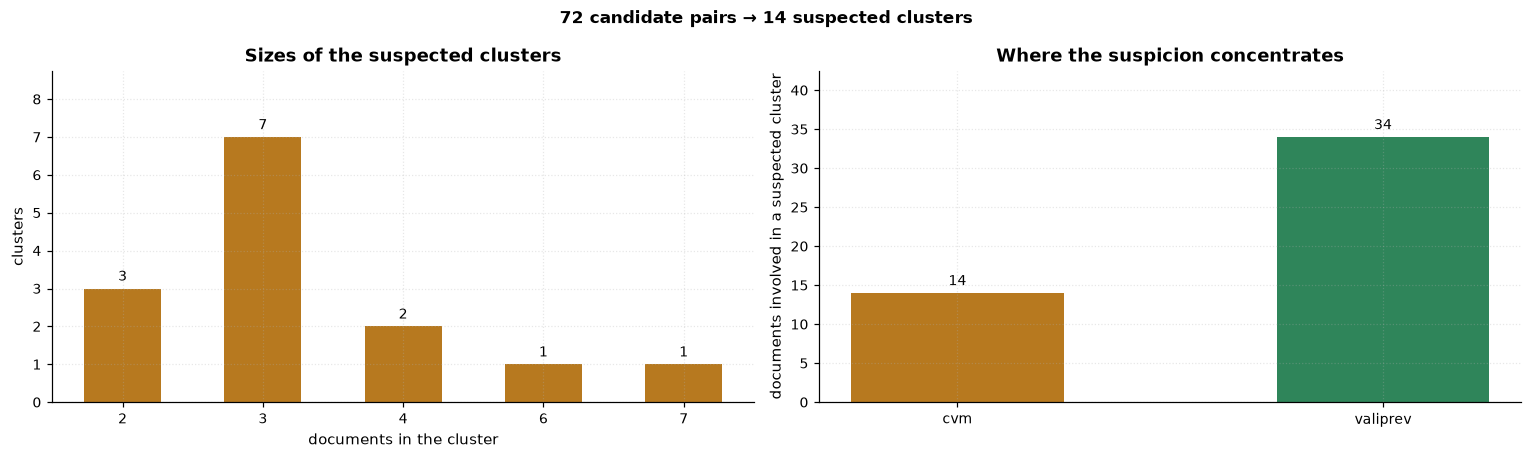

cluster_id,site,copies,wasted if identical,size step,evidence,example
1,valiprev.sp.gov.br,7,2.0 MiB,rounded to ≤ 1 KiB,strong — size is precise,RELATÓRIO_DE_GOVERNANÇA_CORPORATIVA_2023_2024.pdf
2,dados.cvm.gov.br,6,45.0 MiB,rounded to ≤ 1 MiB,weak — size is a wide bucket,dfp_cia_aberta_2011.zip
3,valiprev.sp.gov.br,4,4.2 MiB,exact bytes,strong — size is precise,Plano_de_Capacitação_2019.pdf
4,dados.cvm.gov.br,4,39.0 MiB,rounded to ≤ 1 MiB,weak — size is a wide bucket,dfp_cia_aberta_2021.zip
5,valiprev.sp.gov.br,3,2.8 MiB,exact bytes,strong — size is precise,RELATORIO_GOVERNANCA_2022.pdf
6,valiprev.sp.gov.br,3,7.6 MiB,exact bytes,strong — size is precise,10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO-DAS-ELEICOES-DO
7,valiprev.sp.gov.br,3,168.0 KiB,rounded to ≤ 1 KiB,strong — size is precise,certidao_18853149000189.pdf
8,valiprev.sp.gov.br,3,178.0 KiB,rounded to ≤ 1 KiB,strong — size is precise,Consulta-Regularidade-do-Empregador.pdf
9,valiprev.sp.gov.br,3,564.0 KiB,rounded to ≤ 1 KiB,strong — size is precise,CRP.pdf
10,valiprev.sp.gov.br,3,196.0 KiB,rounded to ≤ 1 KiB,strong — size is precise,EXTRATO-CRP-04-03-2024.pdf


,,clusters,documents involved
site,evidence,,
dados.cvm.gov.br,weak — size is a wide bucket,4,14
valiprev.sp.gov.br,strong — size is precise,10,34


In [6]:
cands = d.load_candidates("outputs")
print(cands[["site", "group", "size", "name_similarity", "kept_url", "candidate_url"]].head(4).to_string(index=False))

# collapse the pairwise rows into clusters of documents that look alike
parent = {}


def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb


for _, r in cands.iterrows():
    union(r["kept_url"], r["candidate_url"])

clusters = {}
for url in parent:
    clusters.setdefault(find(url), []).append(url)

cl = pd.DataFrame(
    {
        "cluster_id": range(1, len(clusters) + 1),
        "urls": [v for v in clusters.values()],
        "copies": [len(v) for v in clusters.values()],
    }
)
from urllib.parse import urlparse

known_hosts = {s: s for s in cands["site"].unique()}


def site_of(url: str) -> str:
    host = urlparse(url).netloc
    for s in known_hosts:
        if host == s or host.endswith("." + s):
            return s
    return "?"


cl["site"] = [site_of(u[0]) for u in cl["urls"]]
cl["example"] = [base(sorted(u)[0])[:52] for u in cl["urls"]]


def _cluster_size(urls):
    # the listed size behind a suspected cluster
    return cands.loc[
        cands["kept_url"].isin(urls) | cands["candidate_url"].isin(urls), "size"
    ].max()


cl["size step"] = [d.size_granularity(_cluster_size(u))[1] for u in cl["urls"]]
cl["evidence"] = [
    "weak — size is a wide bucket"
    if (d.size_granularity(_cluster_size(u))[0] or 1) >= 1024 ** 2
    else "strong — size is precise"
    for u in cl["urls"]
]
cl["wasted if identical"] = [
    d.human_bytes(
        float(cands.loc[cands["kept_url"].isin(u) | cands["candidate_url"].isin(u), "size"].max() or 0)
        * (len(u) - 1)
    )
    for u in cl["urls"]
]
cl = cl.sort_values("copies", ascending=False).reset_index(drop=True)
cl["cluster_id"] = range(1, len(cl) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sizes = cl["copies"].value_counts().sort_index()
axes[0].bar([str(i) for i in sizes.index], sizes.to_numpy(dtype=float), color="#b7791f", width=0.55)
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
axes[0].set_xlabel("documents in the cluster")
axes[0].set_ylabel("clusters")
axes[0].set_title("Sizes of the suspected clusters")
axes[0].set_ylim(0, sizes.max() * 1.25)

per = cl.groupby("site")["copies"].agg(["count", "sum"])
bars = axes[1].bar([d.short_site(s) for s in per.index], per["sum"].to_numpy(dtype=float), color=d.colors_for(per.index), width=0.5)
axes[1].bar_label(bars, padding=3, fontsize=9)
axes[1].set_ylabel("documents involved in a suspected cluster")
axes[1].set_title("Where the suspicion concentrates")
axes[1].set_ylim(0, per["sum"].max() * 1.25)

fig.suptitle(f"{len(cands)} candidate pairs → {len(cl)} suspected clusters", fontweight="bold")
fig.tight_layout()
plt.show()

display(
    cl[["cluster_id", "site", "copies", "wasted if identical", "size step", "evidence", "example"]]
    .head(15)
    .style.hide(axis="index")
)

evidence = cl.groupby(["site", "evidence"])["copies"].agg(["count", "sum"])
display(evidence.rename(columns={"count": "clusters", "sum": "documents involved"}))

## 5 · What a real run would decide

The candidate rows below are the ones worth watching on the first real mirror:
they are the same size *and* essentially the same name, so they are very likely
re-publications — but until a full SHA-256 says so, they are only suspects.

In [7]:
top_c = (
    cands.assign(
        kept=cands["kept_url"].map(base),
        candidate=cands["candidate_url"].map(base),
        size=cands["size"].map(d.human_bytes),
    )[["site", "size", "name_similarity", "kept", "candidate", "reason"]]
    .sort_values(["site", "kept"])
    .head(20)
    .reset_index(drop=True)
)
display(top_c.style.hide(axis="index"))

sim = cands["name_similarity"]
print(f"name similarity: min {sim.min():.2f}, median {sim.median():.2f}, max {sim.max():.2f}")
print(f"rows at similarity 1.00: {(sim == 1.0).sum()} of {len(sim)}")

# the clearest example of what rounding does to the heuristic
import re as _re

years = {}
for _, r in cands.iterrows():
    m = _re.search(r"(\d{4})\.zip$", str(r["kept_url"]))
    n = _re.search(r"(\d{4})\.zip$", str(r["candidate_url"]))
    if m and n:
        years.setdefault(r["size"], set()).update({m.group(1), n.group(1)})
for size, ys in sorted(years.items()):
    if len(ys) > 2:
        print(
            f"\n{len(ys)} different years ({min(ys)}–{max(ys)}) all publish the same size "
            f"{d.human_bytes(size)}: they cannot all be the same file."
        )

site,size,name_similarity,kept,candidate,reason
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2011.zip,dfp_cia_aberta_2012.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2011.zip,dfp_cia_aberta_2013.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2011.zip,dfp_cia_aberta_2014.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2011.zip,dfp_cia_aberta_2015.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2011.zip,dfp_cia_aberta_2016.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2012.zip,dfp_cia_aberta_2013.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2012.zip,dfp_cia_aberta_2014.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2012.zip,dfp_cia_aberta_2015.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2012.zip,dfp_cia_aberta_2016.zip,same listed size + similar name (verify by hash)
dados.cvm.gov.br,9.0 MiB,1.000000,dfp_cia_aberta_2013.zip,dfp_cia_aberta_2014.zip,same listed size + similar name (verify by hash)


name similarity: min 0.73, median 1.00, max 1.00
rows at similarity 1.00: 60 of 72

6 different years (2011–2016) all publish the same size 9.0 MiB: they cannot all be the same file.

4 different years (2021–2024) all publish the same size 13.0 MiB: they cannot all be the same file.


## 6 · The audit question

Which rows should you re-check before trusting a collapse?

1. Every `method = range-probe` row. The probe compared the first and last 64 KiB
   only; a same-size pair that differs in the middle would look identical to it.
   Re-run those sites with `--no-range-probe` when byte-exactness matters. These
   are also the only rows whose payload was never fetched — a wrong guess here
   costs a missing file, not just a wasted download.
2. Every `candidate_duplicates.csv` row once a real mirror exists — compare the
   two files' `sha256` in `manifest.csv` and confirm or dismiss the suspicion.
   Start with the CVM rows: their "same size" is a 1 MiB bucket, so they are the
   likeliest false positives.
3. Nothing else: a `sha256` collapse is exact by construction.

,rows,bytes,sites,verdict
method,,,,
range-probe,3,1.0 MiB,pgfn,heuristic — re-check with --no-range-probe
sha256,6,374.4 KiB,"comissao, cvm, macau, valiprev",exact — full-content digest


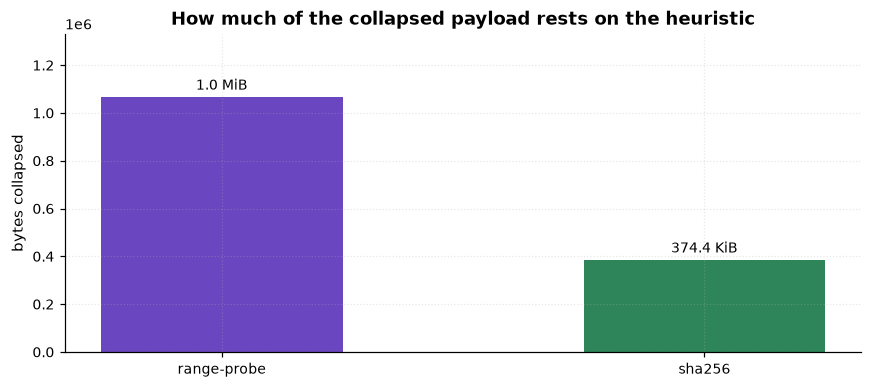

74% of the collapsed payload was decided by the range probe rather than by a full digest.
Only those rows avoided the transfer: 1.0 MiB never crossed the network, while 374.4 KiB was downloaded first and collapsed afterwards.
Re-checking the 3 probe rows costs 1.0 MiB of re-downloading — the price of certainty.


In [8]:
audit = dups.groupby("method").agg(
    rows=("size", "count"),
    bytes=("size", "sum"),
    sites=("site", lambda s: ", ".join(sorted({d.short_site(x) for x in s}))),
)
audit["verdict"] = audit.index.map(
    {"sha256": "exact — full-content digest", "range-probe": "heuristic — re-check with --no-range-probe"}
)
audit["bytes"] = dups.groupby("method")["size"].sum().map(d.human_bytes)
display(audit)

fig, ax = plt.subplots(figsize=(8, 3.6))
vals = dups.groupby("method")["size"].sum()
bars = ax.bar(vals.index, vals.to_numpy(dtype=float), color=["#6b46c1", "#2f855a"], width=0.5)
ax.bar_label(bars, labels=[d.human_bytes(v) for v in vals], padding=3, fontsize=9)
ax.set_ylabel("bytes collapsed")
ax.set_title("How much of the collapsed payload rests on the heuristic")
ax.set_ylim(0, vals.max() * 1.25)
fig.tight_layout()
plt.show()

share = vals.get("range-probe", 0) / vals.sum()
rest = vals.sum() - vals.get("range-probe", 0)
print(f"{share:.0%} of the collapsed payload was decided by the range probe rather than by a full digest.")
print(f"Only those rows avoided the transfer: {d.human_bytes(vals.get('range-probe', 0))} never crossed the network, "
      f"while {d.human_bytes(rest)} was downloaded first and collapsed afterwards.")
print(f"Re-checking the {int((dups['method'] == 'range-probe').sum())} probe rows costs "
      f"{d.human_bytes(vals.get('range-probe', 0))} of re-downloading — the price of certainty.")